# Customer Credit & Spending Analysis

### Importing Relevant Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Dataset Loading

In [2]:
raw_df = pd.read_csv('train_credit.csv', low_memory=False)

## Initial Data Exploration

In [3]:
# Displaying raw df information
raw_df.info()
raw_df.head(15)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good
5,0x1607,CUS_0xd40,June,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,27.262259,22 Years and 6 Months,No,49.574949,62.430172331195294,!@9#%8,340.4792117872438,Good
6,0x1608,CUS_0xd40,July,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,22.537593,22 Years and 7 Months,No,49.574949,178.3440674122349,Low_spent_Small_value_payments,244.5653167062043,Good
7,0x1609,CUS_0xd40,August,NaN,23,#F%$D@*&8,Scientist,19114.12,1824.843333,3,...,Good,809.98,23.933795,NaN,No,49.574949,24.785216509052056,High_spent_Medium_value_payments,358.12416760938714,Standard
8,0x160e,CUS_0x21b1,January,Rick Rothackerj,28_,004-07-5839,_______,34847.84,3037.986667,2,...,Good,605.03,24.464031,26 Years and 7 Months,No,18.816215,104.291825168246,Low_spent_Small_value_payments,470.69062692529184,Standard
9,0x160f,CUS_0x21b1,February,Rick Rothackerj,28,004-07-5839,Teacher,34847.84,3037.986667,2,...,Good,605.03,38.550848,26 Years and 8 Months,No,18.816215,40.39123782853101,High_spent_Large_value_payments,484.5912142650067,Good


## Data Cleaning

In [4]:
# Creating a separate copy containing the columns needed for analysis
columns_to_keep = [
    "ID", "Customer_ID", "Month",
    "Age", "Annual_Income", "Monthly_Inhand_Salary",
    "Outstanding_Debt", "Credit_Utilization_Ratio",
    "Payment_of_Min_Amount", "Credit_Score"
]

clean_df = raw_df[columns_to_keep].copy()

In [5]:
# Counting completely identical rows
print("Duplicate rows:", clean_df.duplicated().sum())

# Checking if any record ID appears more than once
print("Duplicate record IDs:", clean_df["ID"].duplicated().sum())

# Checking for multiple records for the same customer in the same month
print(
    "Duplicate customer-month pairs:",
    clean_df.duplicated(subset=["Customer_ID", "Month"]).sum()
)

Duplicate rows: 0
Duplicate record IDs: 0
Duplicate customer-month pairs: 0


In [6]:
# Removing surrounding underscores and converting numerical text to numbers
numeric_columns = ["Age", "Annual_Income", "Outstanding_Debt"]

for col in numeric_columns:
    clean_df[col] = pd.to_numeric(
        clean_df[col].astype("string").str.strip("_"),
        errors="coerce"
    )

In [7]:
# Replacing ages outside a normal range with missing values
clean_df.loc[
    (clean_df["Age"] < 0) | (clean_df["Age"] > 100),
    "Age"
] = pd.NA

# Flagging unusually high or low incomes using the 3-IQR rule
q1 = clean_df["Annual_Income"].quantile(0.25)
q3 = clean_df["Annual_Income"].quantile(0.75)
iqr = q3 - q1

unusual_income = (
    (clean_df["Annual_Income"] < q1 - 3 * iqr) |
    (clean_df["Annual_Income"] > q3 + 3 * iqr)
)

print("Income values flagged:", unusual_income.sum())

clean_df.loc[unusual_income, "Annual_Income"] = pd.NA

Income values flagged: 999


In [8]:
# Filling missing numerical measurements with their median
measurement_columns = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary",
    "Outstanding_Debt", "Credit_Utilization_Ratio"
]

for col in measurement_columns:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Converting values to text and removing spaces from the beginning and end
clean_df["Payment_of_Min_Amount"] = clean_df["Payment_of_Min_Amount"].astype("string").str.strip()

# Replacing all other entries, including missing values, with "Unknown"
clean_df["Payment_of_Min_Amount"] = clean_df["Payment_of_Min_Amount"].where(
                            clean_df["Payment_of_Min_Amount"].isin(["Yes", "No"]),
                                "Unknown")

# Removing surrounding spaces from credit score labels
clean_df["Credit_Score"] = clean_df["Credit_Score"].astype("string").str.strip()

In [9]:
# Confirming missing values and inspecting the cleaned numerical ranges
print(clean_df.isna().sum())
print(clean_df[measurement_columns].describe())
print("\n")

# Checking the categories used in the analysis
print(clean_df["Payment_of_Min_Amount"].value_counts())
print(clean_df["Credit_Score"].value_counts())

ID                          0
Customer_ID                 0
Month                       0
Age                         0
Annual_Income               0
Monthly_Inhand_Salary       0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Payment_of_Min_Amount       0
Credit_Score                0
dtype: int64
             Age  Annual_Income  Monthly_Inhand_Salary  Outstanding_Debt  \
count   100000.0       100000.0          100000.000000          100000.0   
mean     33.3143   50362.674729            4029.084964       1426.220376   
std    10.628376   38128.506599            2961.363540       1155.129026   
min         14.0        7005.93             303.645417              0.23   
25%         25.0        19457.5            1792.084167          566.0725   
50%         33.0       36993.94            3093.745000          1166.155   
75%         41.0      71367.775            5371.525000         1945.9625   
max        100.0      179987.28           15204.633333           4998.07   

  

In [10]:
# Cleaning focused on the columns needed for analysis.
# Numerical formatting was corrected, impossible ages were marked as missing,
# and extreme incomes were flagged using a conservative statistical rule.
# Missing numerical values were filled with medians, and unclear payment
# categories were labelled Unknown. Filled values are estimates.
# Customers appear across months, so rows represent monthly observations,
# rather than separate customers.

### Final Dataset

In [11]:
# Displaying clean df information
clean_df.info()
clean_df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Age                       100000 non-null  Int64  
 4   Annual_Income             100000 non-null  Float64
 5   Monthly_Inhand_Salary     100000 non-null  float64
 6   Outstanding_Debt          100000 non-null  Float64
 7   Credit_Utilization_Ratio  100000 non-null  float64
 8   Payment_of_Min_Amount     100000 non-null  string 
 9   Credit_Score              100000 non-null  string 
dtypes: Float64(2), Int64(1), float64(2), object(3), string(2)
memory usage: 7.9+ MB


,ID,Customer_ID,Month,Age,Annual_Income,Monthly_Inhand_Salary,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Credit_Score
0,0x1602,CUS_0xd40,January,23,19114.12,1824.843333,809.98,26.822620,No,Good
1,0x1603,CUS_0xd40,February,23,19114.12,3093.745000,809.98,31.944960,No,Good
2,0x1604,CUS_0xd40,March,33,19114.12,3093.745000,809.98,28.609352,No,Good
3,0x1605,CUS_0xd40,April,23,19114.12,3093.745000,809.98,31.377862,No,Good
4,0x1606,CUS_0xd40,May,23,19114.12,1824.843333,809.98,24.797347,No,Good
5,0x1607,CUS_0xd40,June,23,19114.12,3093.745000,809.98,27.262259,No,Good
6,0x1608,CUS_0xd40,July,23,19114.12,1824.843333,809.98,22.537593,No,Good
7,0x1609,CUS_0xd40,August,23,19114.12,1824.843333,809.98,23.933795,No,Standard
8,0x160e,CUS_0x21b1,January,28,34847.84,3037.986667,605.03,24.464031,No,Standard
9,0x160f,CUS_0x21b1,February,28,34847.84,3037.986667,605.03,38.550848,No,Good


## Data Analysis

### 1. Does the relationship between outstanding debt and credit score differ across income groups?

In [12]:
# Dividing records into three approximately equal-sized income groups
clean_df["Income_Group"] = pd.qcut(
    clean_df["Annual_Income"],
    q=3,
    labels=["Low income", "Middle income", "High income"]
)

# Dividing records into three approximately equal-sized debt groups
clean_df["Debt_Group"] = pd.qcut(
    clean_df["Outstanding_Debt"],
    q=3,
    labels=["Low debt", "Middle debt", "High debt"]
)

# Checking the numerical ranges represented by each group
print(clean_df.groupby("Income_Group", observed=True)["Annual_Income"].describe()[["min", "max", "count"]])
print(clean_df.groupby("Debt_Group", observed=True)["Outstanding_Debt"].describe()[["min", "max", "count"]])

                   min        max    count
Income_Group                              
Low income     7005.93   25417.33  33333.0
Middle income  25428.7   59393.36  33337.0
High income    59412.6  179987.28  33330.0
                 min      max    count
Debt_Group                            
Low debt        0.23   768.25  33336.0
Middle debt   768.36  1470.65  33336.0
High debt    1470.72  4998.07  33328.0


In [13]:
# Marking poor credit scores as True and all other scores as False
clean_df["Poor_Score"] = clean_df["Credit_Score"] == "Poor"

# Calculating the number of records and percentage with poor credit scores
q1_results = (
    clean_df.groupby(["Income_Group", "Debt_Group"], observed=True)
    .agg(
        Records=("Poor_Score", "size"),
        Poor_Percentage=("Poor_Score", "mean")
    )
)

# Converting proportions into percentages
q1_results["Poor_Percentage"] = (q1_results["Poor_Percentage"] * 100).round(2)

print(q1_results)

                           Records  Poor_Percentage
Income_Group  Debt_Group                           
Low income    Low debt        8010             9.14
              Middle debt     8778            23.55
              High debt      16545            59.71
Middle income Low debt       11054            10.76
              Middle debt    11328            16.08
              High debt      10955            60.49
High income   Low debt       14272            11.29
              Middle debt    13230            13.45
              High debt       5828            56.49


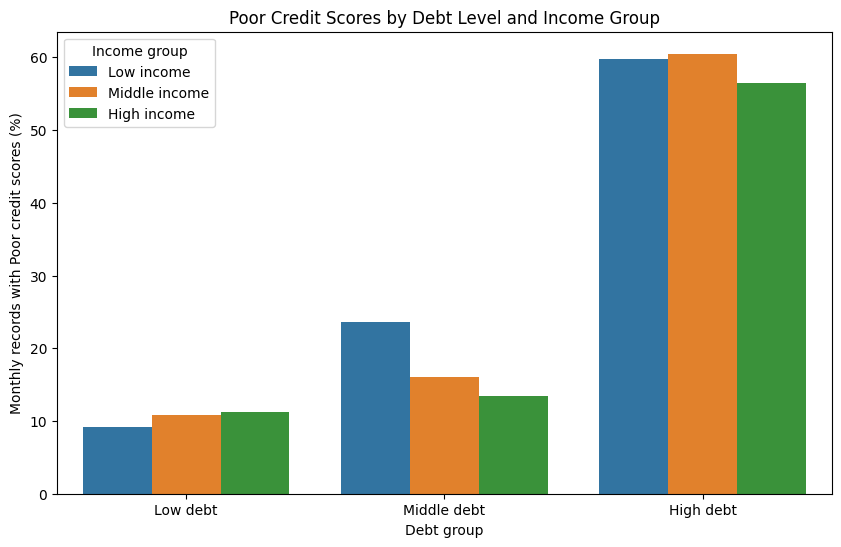

In [14]:
# Turning the grouped results into a regular table for Seaborn
plot_data = q1_results.reset_index()

# Comparing poor-score percentages across debt and income groups
plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Debt_Group",
    y="Poor_Percentage",
    hue="Income_Group",
    errorbar=None
)

plt.title("Poor Credit Scores by Debt Level and Income Group")
plt.xlabel("Debt group")
plt.ylabel("Monthly records with Poor credit scores (%)")
plt.legend(title="Income group")
plt.show()

`Poor credit scores are much more common among high-debt records (56–60%) than low-debt records (9–11%), regardless of income group. At middle debt levels, higher income is associated with fewer Poor scores, but this difference is smaller at high debt levels. This suggests that debt and income should be considered together when interpreting credit outcomes. The results show an association, rather than proving that debt causes Poor credit scores.`

### 2. Among high-income records, what distinguishes Poor credit scores from Good scores?

In [15]:
# Selecting high-income records with Poor or Good credit scores
high_income_df = clean_df[
    (clean_df["Income_Group"] == "High income") &
    (clean_df["Credit_Score"].isin(["Poor", "Good"]))
].copy()

In [16]:
# Comparing typical financial measurements between the two score categories
q2_results = high_income_df.groupby("Credit_Score")[
    ["Outstanding_Debt", "Credit_Utilization_Ratio", "Monthly_Inhand_Salary"]
].median().round(2)

print(q2_results)

# Checking how many monthly records contribute to each group
print(high_income_df["Credit_Score"].value_counts())

              Outstanding_Debt  Credit_Utilization_Ratio  \
Credit_Score                                               
Good                    724.81                     33.63   
Poor                   1461.38                     33.03   

              Monthly_Inhand_Salary  
Credit_Score                         
Good                        7564.72  
Poor                        6074.40  
Credit_Score
Good    8108
Poor    6682
Name: count, dtype: Int64


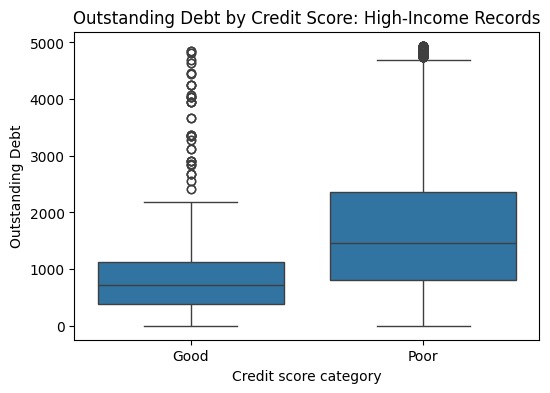

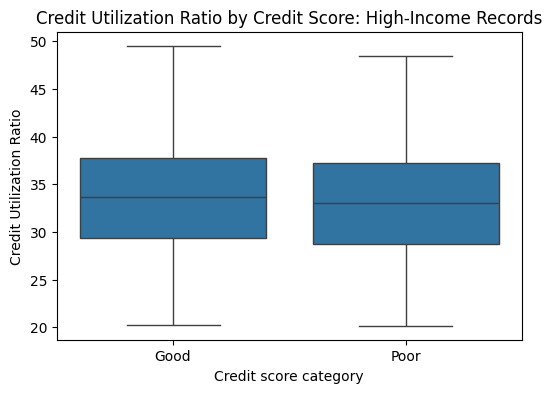

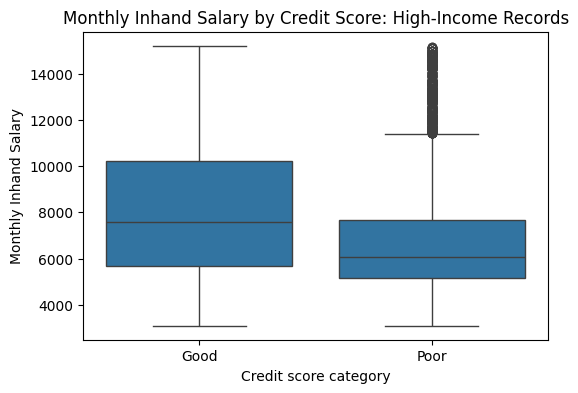

In [17]:
# Comparing each measurement between Good and Poor credit scores
for col in ["Outstanding_Debt", "Credit_Utilization_Ratio", "Monthly_Inhand_Salary"]:
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=high_income_df,
        x="Credit_Score",
        y=col,
        order=["Good", "Poor"]
    )

    plt.title(f"{col.replace('_', ' ')} by Credit Score: High-Income Records")
    plt.xlabel("Credit score category")
    plt.ylabel(col.replace("_", " "))
    plt.show()

`Among high-income records, those with Poor credit scores have roughly twice the median outstanding debt of those with Good scores (1,461 versus 725), alongside lower median monthly salaries (6,074 versus 7,565). Credit utilisation has similar medians and substantial overlap between the groups, so it provides little distinction here. These findings suggest that debt and salary should be considered alongside annual income when interpreting credit outcomes, although they do not establish causation.`

## 3. Within similar debt groups, how does minimum-payment behaviour relate to credit scores?

In [18]:
# Using records with a known minimum-payment category
payment_df = clean_df[
    clean_df["Payment_of_Min_Amount"].isin(["Yes", "No"])
].copy()

# Counting records and calculating the poor-score percentage in each group
q3_results = (
    payment_df.groupby(
        ["Debt_Group", "Payment_of_Min_Amount"],
        observed=True
    )
    .agg(
        Records=("Poor_Score", "size"),
        Poor_Percentage=("Poor_Score", "mean")
    )
)

# Converting proportions into percentages
q3_results["Poor_Percentage"] = (q3_results["Poor_Percentage"] * 100).round(2)

print(q3_results)

                                   Records  Poor_Percentage
Debt_Group  Payment_of_Min_Amount                          
Low debt    No                       18775            13.35
            Yes                      10609             5.83
Middle debt No                       16269            13.25
            Yes                      13003            21.56
High debt   No                         623            17.66
            Yes                      28714             60.2


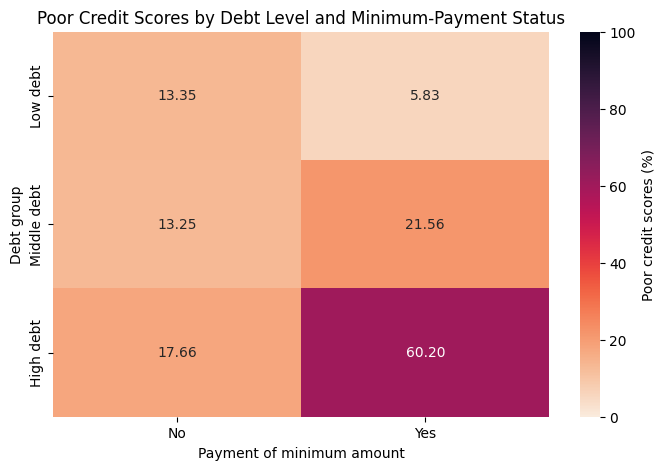

In [19]:
# Arranging payment categories as columns and debt groups as rows
heatmap_data = q3_results["Poor_Percentage"].unstack("Payment_of_Min_Amount").astype(float)

# Displaying the percentage of poor credit scores in each combination
plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="rocket_r",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Poor credit scores (%)"}
)

plt.title("Poor Credit Scores by Debt Level and Minimum-Payment Status")
plt.xlabel("Payment of minimum amount")
plt.ylabel("Debt group")
plt.show()

`Making the minimum payment is associated with fewer Poor credit scores in the low-debt group, but more Poor scores in the middle- and high-debt groups. The highest percentage is among high-debt records marked “Yes” (60.20%). This shows why payment status should be considered alongside debt level. It does not mean that paying the minimum causes poorer scores, and the high-debt “No” group is much smaller.`

### 4. When a customer’s credit score improves or worsens between months, how does their credit utilisation change?

In [20]:
# Creating a separate table for comparing monthly changes
changes_df = clean_df.copy()

# Converting month names into numbers so they sort chronologically
month_numbers = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12
}

changes_df["Month_Number"] = changes_df["Month"].map(month_numbers)

changes_df = changes_df.sort_values(["Customer_ID", "Month_Number"])

In [21]:
# Representing credit score categories in their natural order
changes_df["Score_Order"] = changes_df["Credit_Score"].map({
    "Poor": 0, "Standard": 1, "Good": 2
})

# Calculating changes within each customer's records
columns = [
    "Score_Order", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Month_Number"
]

monthly_changes = changes_df.groupby("Customer_ID")[columns].diff()

# Keeping only comparisons between consecutive months
changes_df["Score_Change"] = monthly_changes["Score_Order"]
changes_df["Debt_Change"] = monthly_changes["Outstanding_Debt"]
changes_df["Utilisation_Change"] = monthly_changes["Credit_Utilization_Ratio"]

# Keeping only neighbouring months
changes_df = changes_df[monthly_changes["Month_Number"] == 1].copy()

# Labelling whether the score improved, worsened or stayed the same
changes_df["Score_Direction"] = "Unchanged"
changes_df.loc[changes_df["Score_Change"] > 0, "Score_Direction"] = "Improved"
changes_df.loc[changes_df["Score_Change"] < 0, "Score_Direction"] = "Worsened"

In [22]:
q4_results = changes_df.groupby("Score_Direction").agg(
    Median_Debt_Change=("Debt_Change", "median"),
    Median_Utilisation_Change=("Utilisation_Change", "median")).round(3)

print(q4_results)

                 Median_Debt_Change  Median_Utilisation_Change
Score_Direction                                               
Improved                        0.0                     -0.076
Unchanged                       0.0                      0.002
Worsened                        0.0                      0.109


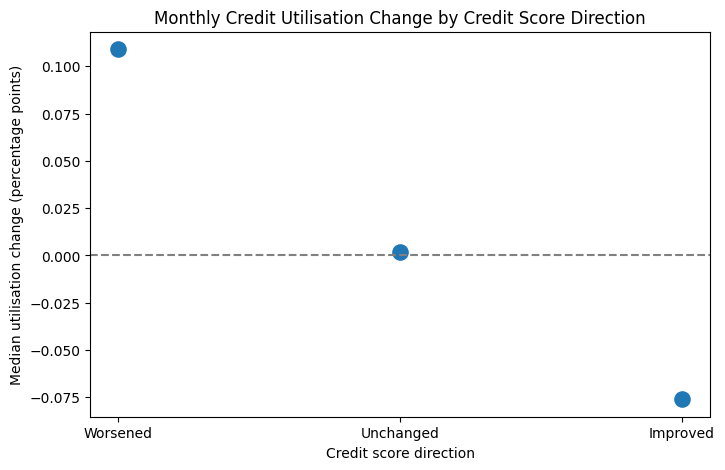

In [23]:
# Arranging the groups from worsened to improved
plot_data = q4_results.reindex(["Worsened", "Unchanged", "Improved"])

# Plotting the median utilisation change for each group
plt.figure(figsize=(8, 5))

plt.scatter(
    plot_data.index,
    plot_data["Median_Utilisation_Change"],
    s=120
)

# Adding a reference line showing no change
plt.axhline(0, color="grey", linestyle="--")

plt.title("Monthly Credit Utilisation Change by Credit Score Direction")
plt.xlabel("Credit score direction")
plt.ylabel("Median utilisation change (percentage points)")
plt.show()

`Months when credit scores worsened had a small median increase in credit utilisation (+0.109 percentage points), while improvements coincided with a small decrease (−0.076). Unchanged scores showed almost no median change. These differences are too small to draw strong conclusions, so utilisation changes alone provide limited insight into monthly score movements.`

### 5. Within similar income groups, do younger and older customers have different percentages of Poor credit scores?

In [24]:
# Creating age groups
age_df = clean_df[clean_df["Age"].between(18, 80)].copy()

# Dividing ages into three groups
age_df["Age_Group"] = pd.cut(
    age_df["Age"],
    bins=[18, 30, 45, 81],
    labels=["18–29", "30–44", "45–80"],
    right=False
)

# Counting records and calculating the proportion of poor scores in each group
q5_results = (
    age_df.groupby(["Age_Group", "Income_Group"], observed=True)
    .agg(
        Records=("Poor_Score", "size"),
        Poor_Percentage=("Poor_Score", "mean")
    )
)

# Converting proportions into percentages
q5_results["Poor_Percentage"] = (q5_results["Poor_Percentage"] * 100).round(2)

print(q5_results)

                         Records  Poor_Percentage
Age_Group Income_Group                           
18–29     Low income       11270            40.28
          Middle income    11160             30.3
          High income      10729            22.54
30–44     Low income       15597             39.4
          Middle income    14545             30.7
          High income      14425            20.33
45–80     Low income        3997            18.74
          Middle income     5665            16.06
          High income       6901            12.91


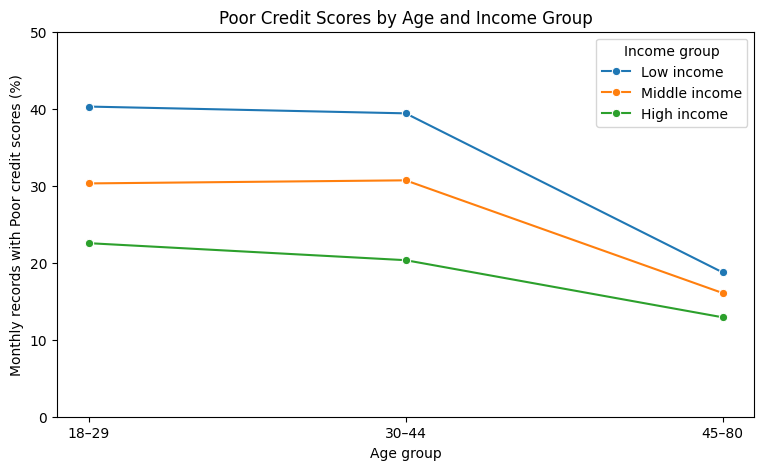

In [25]:
# Preparing the grouped results for plotting
plot_data = q5_results.reset_index()

# Comparing poor-score percentages across age groups for each income group
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=plot_data,
    x="Age_Group",
    y="Poor_Percentage",
    hue="Income_Group",
    marker="o"
)

plt.title("Poor Credit Scores by Age and Income Group")
plt.xlabel("Age group")
plt.ylabel("Monthly records with Poor credit scores (%)")
plt.ylim(0, 50)
plt.legend(title="Income group")
plt.show()

`Poor credit scores are less common in the 45–80 age group across all income levels, while the two younger groups show similar percentages. Higher income is also associated with fewer Poor scores within every age group.`